In [1]:
%load_ext autoreload
%autoreload 2
import sys
from sc_foi.bbq.bbq_circuit_fitting import BlackBoxAdmittanceModel, TwoCavityOneCouplerModel

In [2]:
import os
import numpy as np
from lmfit import create_params

# Fitting two modes

In [38]:
ljs = np.logspace(np.log10(1e-2 * 1e-9), np.log10(1e4 * 1e-9), 200)
bbq_am_two = BlackBoxAdmittanceModel(admittance_filename="../../data/ydata_open_circuit_mumachined_degenerate.csv",
                                ljs=ljs, n_modes=2)

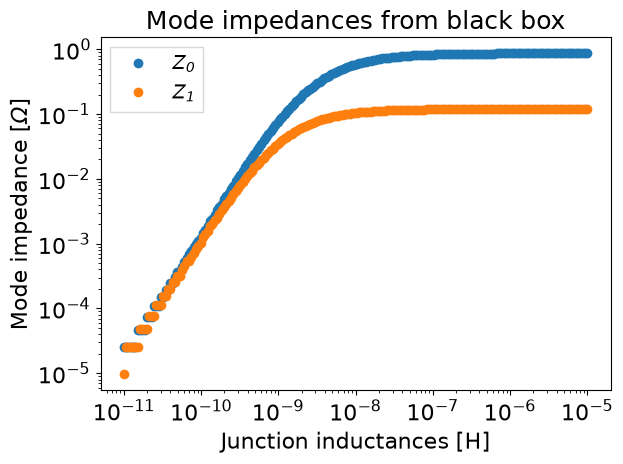

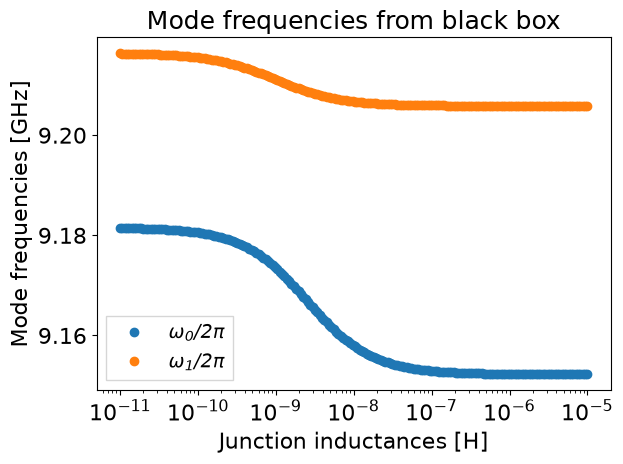

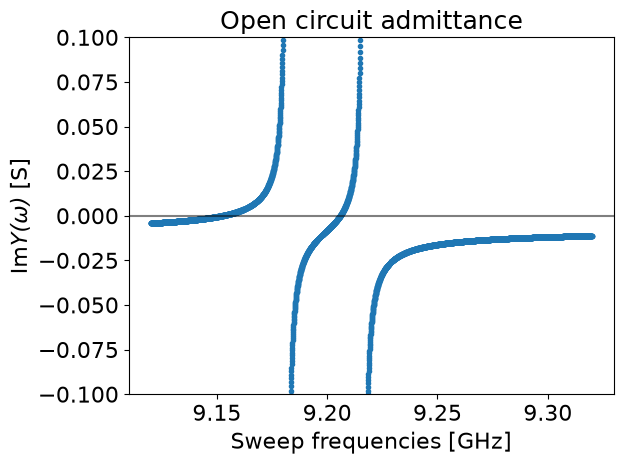

In [39]:
bbq_am_two.run()

# Fitting three modes

In [10]:
ljs = np.logspace(np.log10(1e-2 * 1e-9), np.log10(1e4 * 1e-9), 200)
bbq_am_three = BlackBoxAdmittanceModel(admittance_filename="../../data/ydata_open_circuit_mumachined_degenerate_with_coupler.csv",
                                ljs=ljs, n_modes=3)

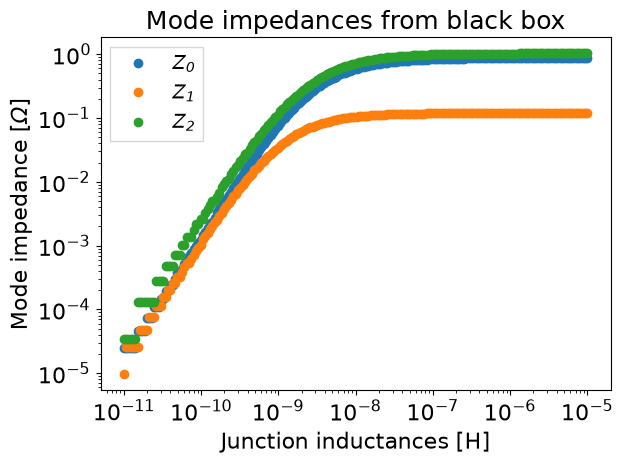

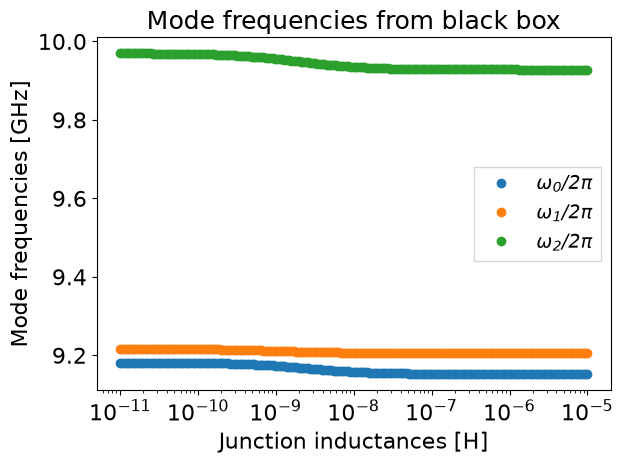

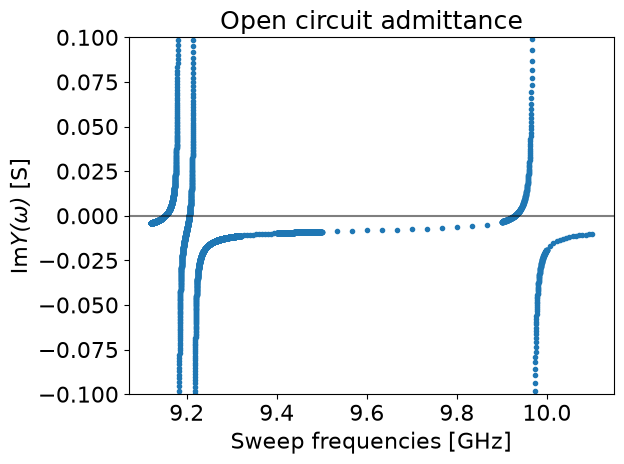

In [11]:
bbq_am_three.run()

## Fit the mode impedances

In [12]:
mode_index = 0
unit_scale = 1e9
zp = bbq_am_three.mode_impedances[:, mode_index]
zps = bbq_am_three.mode_impedances
wps = bbq_am_three.mode_frequencies / unit_scale
circ_model = TwoCavityOneCouplerModel(data=zps, x=ljs * unit_scale, unit_scale=unit_scale, wp_data=wps)

In [13]:
fit_result = circ_model.minimize() # method="differential_evolution")

In [14]:
fit_result.params

name,value,standard error,relative error,initial value,min,max,vary
l1,0.10000000,0.00000000,(0.00%),0.1,0.10000000,inf,True
l2,0.30000000,4298.44137,(1432813.79%),0.3,0.10000000,inf,True
l1c,0.10000000,0.00000000,(0.00%),0.1,0.10000000,inf,True
l2c,0.10000000,0.00000000,(0.00%),0.1,0.10000000,inf,True
c1,0.30000000,953.981356,(317993.79%),0.3,1.0000e-04,inf,True
c2,0.10000000,573.282367,(573282.37%),0.1,1.0000e-04,inf,True
cj,0.00200000,7.4905e-04,(37.45%),0.002,1.0000e-04,inf,True


params = Parameters([('l1', <Parameter 'l1', value=0.1 +/- 0, bounds=[0.1:inf]>), ('l2', <Parameter 'l2', value=0.29999999999999993 +/- 4.3e+03, bounds=[0.1:inf]>), ('l1c', <Parameter 'l1c', value=0.1 +/- 0, bounds=[0.1:inf]>), ('l2c', <Parameter 'l2c', value=0.1 +/- 0, bounds=[0.1:inf]>), ('c1', <Parameter 'c1', value=0.30000000000000004 +/- 954, bounds=[0.0001:inf]>), ('c2', <Parameter 'c2', value=0.10000000000000009 +/- 573, bounds=[0.0001:inf]>), ('cj', <Parameter 'cj', value=0.0020000000000000018 +/- 0.000749, bounds=[0.0001:inf]>)])


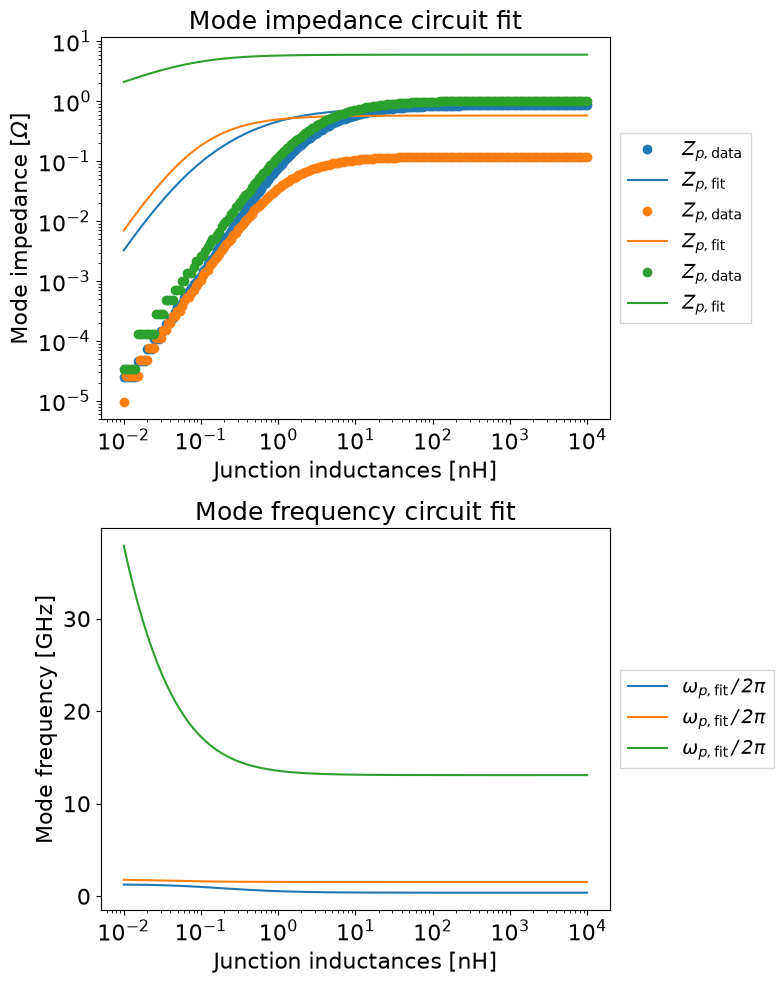

In [15]:
circ_model.plot_fit(params=fit_result.params)